In [ ]:
from evaluation_utils import *
RESULTS_PATH = os.path.join(RESULTS_DIR, "pendulum_different")

In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:////" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True)

best_trial = get_trial_by_number(study.trials, idx_best_trial) 
print("Parameters:")
for param in param_importances.keys():
    print(f"{param} imp: {param_importances[param]:.4f}, best: {best_trial.params.get(param)}")
#remove_pruned_trial_folders(study, RESULTS_PATH)

## Evaluation

In [5]:
from src.models.mtf_model import MTFModel
from src.main import init_dataset
from src.environments.pendulum import Hamiltonian, transform_to_cartesian

DEVICE = tc.device("cpu")
RUN = "001"
# load test set
full = tc.as_tensor(np.load(DATA_DIR + "/multi_task_double_pendulum/default/full.npy", allow_pickle=True))
PENDULUM_PARAMETERS = np.load(DATA_DIR + "/multi_task_double_pendulum/default/params.npy", allow_pickle=True)
DATASET = init_dataset(json.load(open(RESULTS_DIR + '/pendulum_different/params_ldim=106_relu=84_feature_dim=4_dsr_lr=0p00_lr_gamma=1p00_gtf=0p04_gtf_gamma=1p00_aent=8p60_adsr=210p04_ac=4p61_seqlen=30/001/config.json')), DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX = {DATASET.evaluator_test_samples[i].measurement_index: DATASET.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(DATASET.evaluator_test_samples)-1, -1, -1)}

Sequence length set to 30.


In [6]:
def generate_from_pendulum_model(model, T=11000):
    time_series_per_measurement = full.shape[1]
    trajectories = tc.zeros((16, time_series_per_measurement, T, 6))
    latent_trajectories = tc.zeros((16, time_series_per_measurement, T, model.dsr_model.hyperparameters["latent_dim"]))

    for measurement_index in range(16):
        for time_series_index in range(time_series_per_measurement):
            (latent_trajectory,
            _,
            trajectory,
            ) = (
            model.generate_free_trajectory(
                full[measurement_index][time_series_index],
                DATASET.evaluator_test_samples[measurement_index*4].cumulative_timeseries_index,
                DATASET.evaluator_test_samples[measurement_index*4].measurement_index,
                T=T,
            )[:3]
            )
            trajectory = trajectory[:].detach().cpu()
            latent_trajectory = latent_trajectory[:].detach().cpu()

            trajectories[measurement_index, time_series_index, :] = trajectory
            latent_trajectories[measurement_index, time_series_index, :] = latent_trajectory
    return trajectories, latent_trajectories

def evaluate_pendulum_model(trajectories, compute_klx=True):
    mse_ = []
    energy_error_ = []
    klx_ = []
    pse_ = []
    
    for i in range(len(trajectories)):
        for k in range(trajectories[i].shape[0]):
            #if k %2 == 0: continue
            energy, kin_energy = Hamiltonian(trajectories[i, k], params=PENDULUM_PARAMETERS[i])[:2]
            energy_error = tc.diff(tc.abs(energy[:270] -energy[0])).max()
            #energy_error /= tc.mean(tc.abs(kin_energy))
            energy_error_.append(energy_error)
            
            mse = tc.mean((trajectories[i, k][:270] - full[i, k][:270])**2).item()
            mse_.append(mse)
            
            if compute_klx:
                #klx = state_space_divergence_gmm(trajectories[i, k][1000:], full[i, k][1000:6000]).item()
                klx = klx_bin(trajectories[i, k][1000:11000], full[i, k][:]).item()
            else:
                klx = 0
            klx_.append(klx)
            
            pse = power_spectrum_error(trajectories[i, k][1000:11000], full[i, k][:],  smoothing_sigma=5, freq_cutoff=1001).item()
            pse_.append(pse)
    return mse_, energy_error_, klx_, pse_

In [8]:
eval_dict = {}
candidates = [subpath for subpath in os.listdir(RESULTS_PATH) if subpath.startswith("params_") and "001" in os.listdir(os.path.join(RESULTS_PATH, subpath))
              and "model_5000.pt" in os.listdir(os.path.join(RESULTS_PATH, subpath, RUN))]

for i, subpath in enumerate(candidates):
    print(subpath)
        
    # load model
    run_path = os.path.join(RESULTS_PATH, subpath, RUN)
    parameters = json.load(open(f"{run_path}/config.json"))
    model = MTFModel(DATASET, model_path=run_path, device=DEVICE)

    trajectories, latent_trajectories = generate_from_pendulum_model(model)
    # if any trajectory contains NaN, skip this model
    if any(tc.isnan(trajectory).any() for trajectory in trajectories):
        continue
    
    eval_dict[subpath] = {"id": i, "trajectories": trajectories, "latent_trajectory": latent_trajectories, "subject_vectors": model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()}

params_ldim=106_relu=84_feature_dim=4_dsr_lr=0p00_lr_gamma=1p00_gtf=0p04_gtf_gamma=1p00_aent=8p60_adsr=210p04_ac=4p61_seqlen=30
Encoder model parameters: 11200
DSR model parameters: 45856
Decoder model parameters: 0


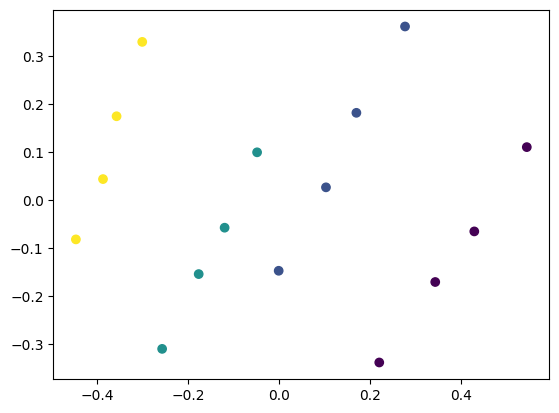

Energy Error: 3.1068, mse: 4.8451,
 kl: 0.0000, pse: 0.2245, pca: 0.91, Subpath: params_ldim=106_relu=84_feature_dim=4_dsr_lr=0p00_lr_gamma=1p00_gtf=0p04_gtf_gamma=1p00_aent=8p60_adsr=210p04_ac=4p61_seqlen=30


In [10]:
pendulum_parameters = np.load(DATA_DIR + "/multi_task_double_pendulum/default/params.npy", allow_pickle=True)
colors = [(pendulum_parameters[i]["m1"]/pendulum_parameters[i]["m2"], pendulum_parameters[i]["l1"]/pendulum_parameters[i]["l2"]) for i in range(16)]

for k, subpath in enumerate(eval_dict.keys()):
    trajectories = eval_dict[subpath]["trajectories"]
    
    if len(trajectories) < 16:
        try:
            print("Removing")
            #shutil.rmtree(os.path.join(RESULTS_PATH, subpath))
        except:
            pass
        continue
    mse_, energy_error_, klx_, pse_ = evaluate_pendulum_model(trajectories, compute_klx=False)
    if np.nanmax(energy_error_) > 100:
        try:
            print("Removing")
            #shutil.rmtree(os.path.join(RESULTS_PATH, subpath))
        except:
            pass
        continue
    
    pca = PCA(n_components=2)
    subject_vectors = eval_dict[subpath]["subject_vectors"]
    subject_vectors_2d = pca.fit_transform(subject_vectors)
    plt.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=[colors[i][1] for i in range(16)], cmap="viridis", label="Subject Vectors")
    plt.show()
    plt.close()

    print("Energy Error: {:.4f}, mse: {:.4f},\n kl: {:.4f}, pse: {:.4f}, pca: {:4.2f}, Subpath: {}".format(np.nanmedian(energy_error_), np.nanmedian(mse_), np.nanmedian(np.reshape(klx_, (16, 50)).mean(axis=1)), np.nanmedian(pse_), np.sum(pca.explained_variance_ratio_[:3]), subpath))


## Analysis

In [ ]:
trial = get_trial_by_number(study.trials, 192)
trial_folder_name = "params_" + \
    "_".join([(f"{key}={ValueFormatter._formatted_value(value)}")
             for key, value in trial.params.items()])
print(trial_folder_name)
trial_folder_name = "params_ldim=106_relu=84_feature_dim=4_dsr_lr=0p00_lr_gamma=1p00_gtf=0p04_gtf_gamma=1p00_aent=8p60_adsr=210p04_ac=4p61_seqlen=30"

params_ldim=106_relu=84_feature_dim=4_dsr_lr=0p00_lr_gamma=1p00_gtf=0p04_gtf_gamma=1p00_aent=4p97_adsr=217p63_ac=0p13_seqlen=30


In [12]:
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)
parameters = json.load(open(f"{run_path}/config.json"))
model = MTFModel(DATASET, model_path=run_path, device=DEVICE)

Encoder model parameters: 11200
DSR model parameters: 45856
Decoder model parameters: 0


In [13]:
trajectories_train = []
trajectories_val = []
trajectories_test = []


for time_series_index in range(len(DATASET.evaluator_train_samples)):
    observations_train = DATASET.evaluator_train_samples[time_series_index].input
    measurement_index = DATASET.evaluator_train_samples[time_series_index].measurement_index
    cumulative_timeseries_index = DATASET.evaluator_train_samples[time_series_index].cumulative_timeseries_index

    trajectory = model.generate_free_trajectory(
        observations_train,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[2].detach().cpu()
    trajectories_train.append(trajectory)

for time_series_index in range(len(DATASET.evaluator_test_samples)):
    observations_val = DATASET.evaluator_test_samples[time_series_index].input
    measurement_index = DATASET.evaluator_test_samples[time_series_index].measurement_index
    cumulative_timeseries_index = DATASET.evaluator_test_samples[time_series_index].cumulative_timeseries_index

    trajectory = model.generate_free_trajectory(
        observations_val,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[2].detach().cpu()
    trajectories_val.append(trajectory)
    
for i in range(16):
    observations_test = full[i, 1, :600]
    measurement_index = i
    cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
    #observations_test[0] =tc.randn(6)
    trajectory = model.generate_free_trajectory(
        observations_test,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[2].detach().cpu()
    trajectories_test.append(trajectory)

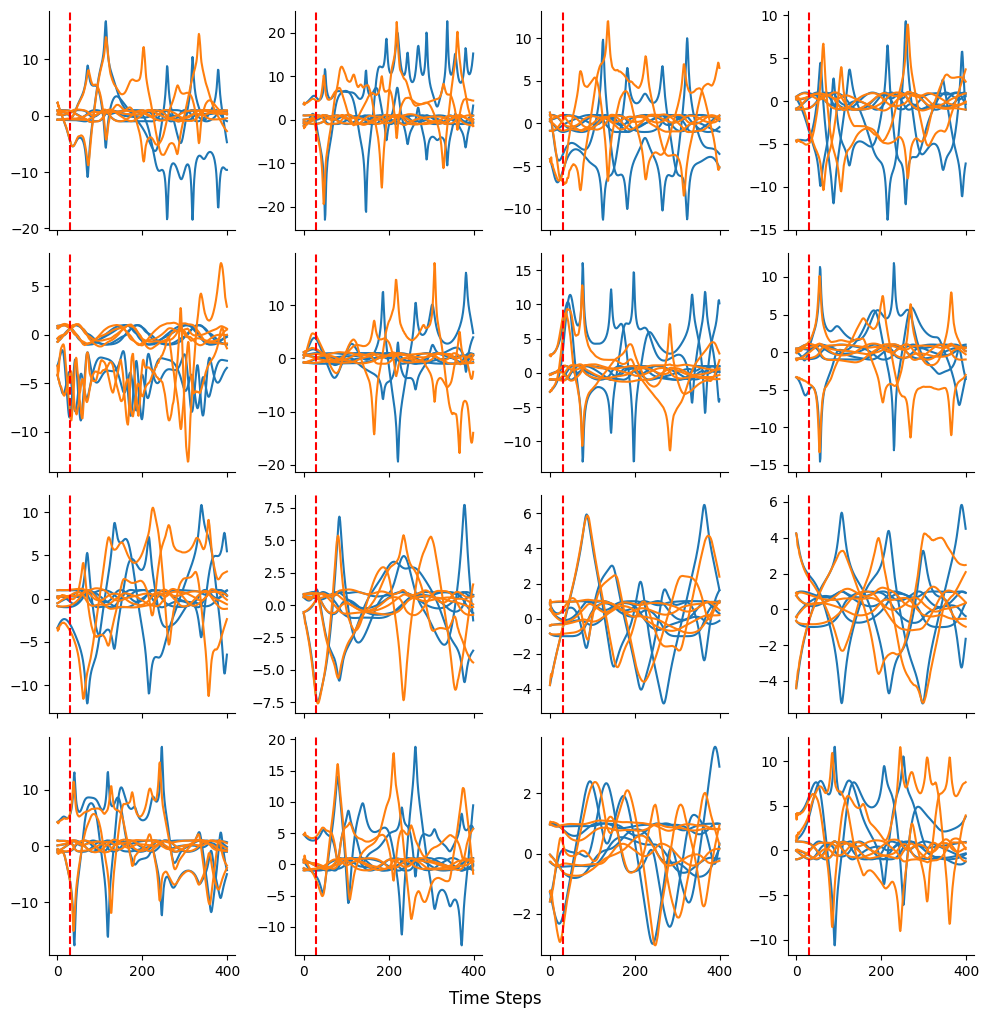

In [14]:
fig, axs = plt.subplots(4, 4, figsize=(10, 10), sharex=True, sharey=False)
for i in range(4):
    for j in range(4):
        idx = (i * 4 + j)
        axs[i, j].plot(full[idx, 1, :400][:, ], c="C0")
        axs[i, j].plot(trajectories_test[idx][:400], c="C1")
        axs[i, j].axvline(30, color='red', linestyle='--')
        
for ax in axs.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
fig.text(0.5, -0.01, 'Time Steps', ha='center', fontsize=FONT_SIZE)
plt.tight_layout()
plt.show()
#save_fig(fig, "pendulum_reconstruction_all")

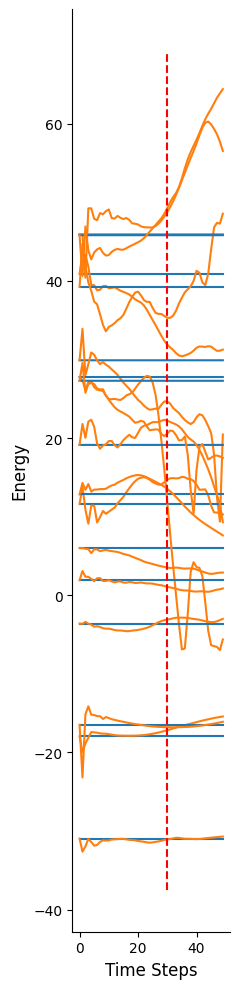

In [15]:
fig = plt.figure(figsize=(2.5, 10))
for i in range(16):
    energy = Hamiltonian(full[i][1][:50], params=pendulum_parameters[i])[0]
    plt.plot(energy, c="C0")
    energy = Hamiltonian(trajectories_test[i][:50], params=pendulum_parameters[i])[0]
    plt.plot(energy, c="C1")

plt.vlines(30, ymin=plt.ylim()[0], ymax=plt.ylim()[1], color='red', linestyle='--', )
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel("Time Steps", fontsize=FONT_SIZE)
plt.ylabel("Energy", fontsize=FONT_SIZE)
plt.tight_layout()
plt.show()
#save_fig(fig, "pendulum_energy_reconstruction_all")

In [5]:
align_pdf_figures([
    FIG_DIR + "/pendulum_reconstruction_all_width_96_height_99.pdf",
    FIG_DIR + "/pendulum_energy_reconstruction_all_width_21_height_97.pdf",
],
    output_pdf="combined_figures9.pdf",
    rows=1,
)

PosixPath('figures_new/combined_figures9.pdf')

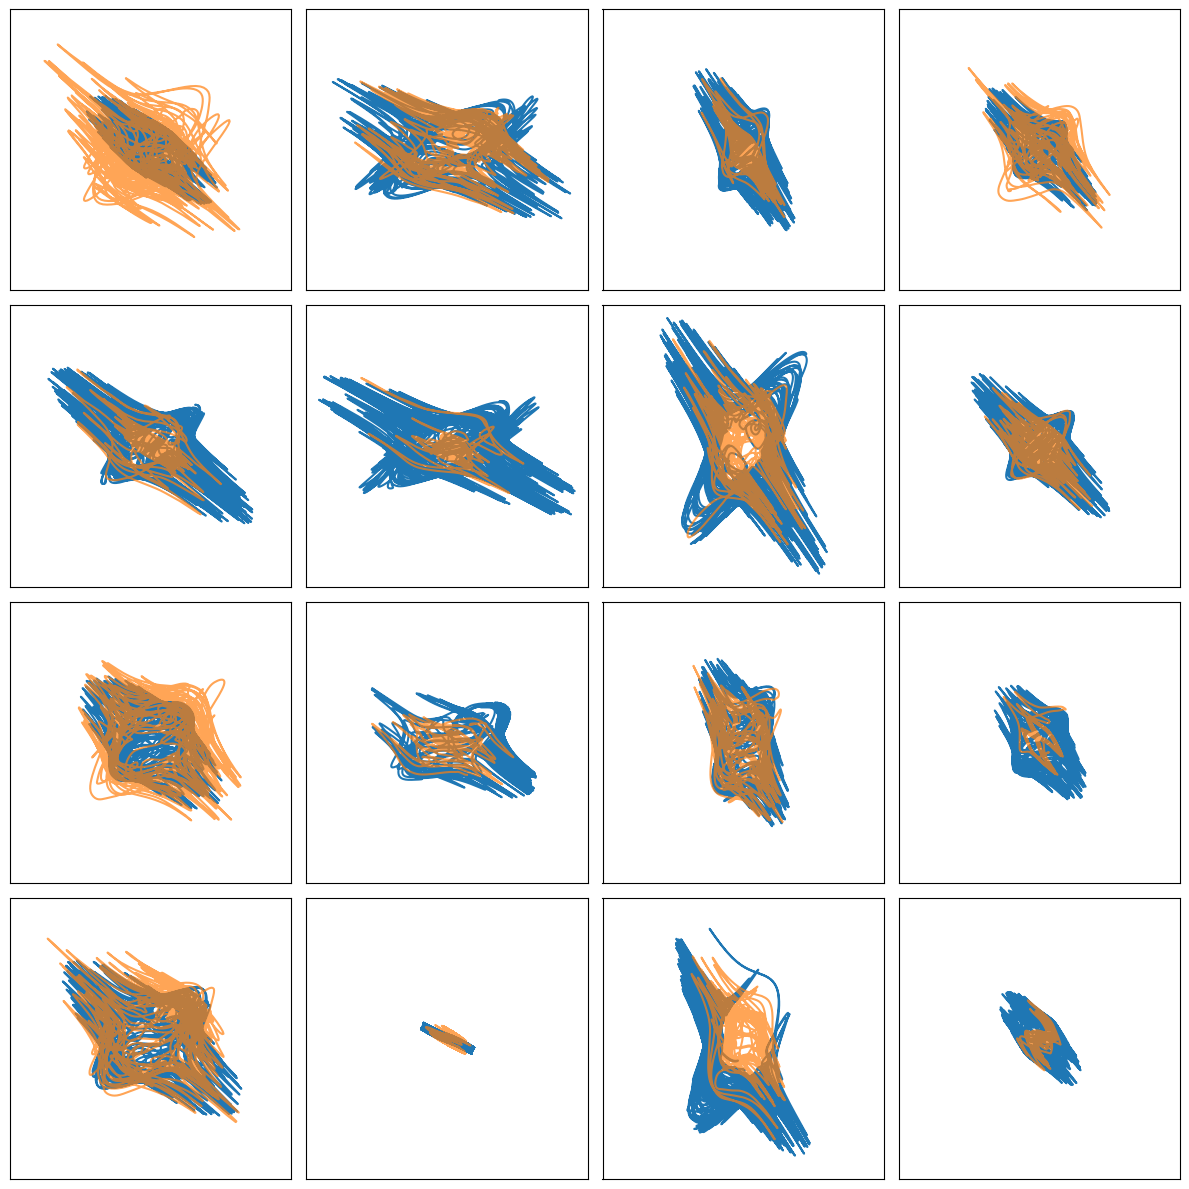

In [49]:
# Define shared limits
xlim = (-2, 1)
ylim = (-2, 4)

fig, axs = plt.subplots(4, 4, figsize=(12, 12), sharex=True, sharey=True)
for i in range(16):
    ax = axs[i // 4, i % 4]
    
    full_velocities = full[i, 46][:, -2:]
    trajectories_test_velocities = eval_dict[trial_folder_name]["trajectories"][i, 46].numpy()[:, -2:]
    
    # Plot data
    ax.plot(full_velocities[:, 0], full_velocities[:, 1])
    ax.plot(trajectories_test_velocities[:, 0], trajectories_test_velocities[:, 1], alpha=0.7)

    # Remove tick labels
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    # Optionally remove ticks entirely:
    ax.set_xticks([])
    ax.set_yticks([])

plt.subplots_adjust(wspace=-0.5, hspace=-0.7, right=1, left=0, top=1, bottom=0)
plt.tight_layout()
plt.show()

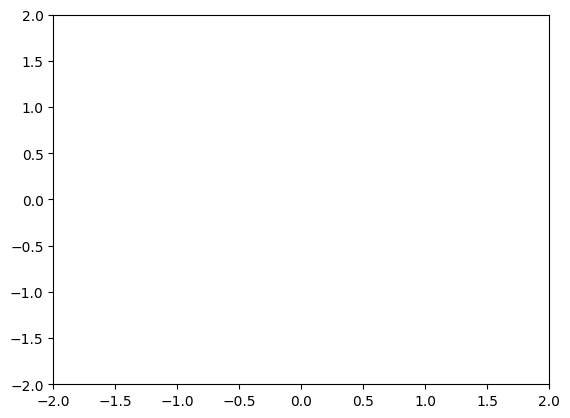

In [ ]:
# integrate
from matplotlib.animation import FuncAnimation

measurement_index = 0
trajectories_test_cartesian = transform_to_cartesian(trajectories_test[measurement_index].numpy(), parameters = pendulum_parameters[measurement_index])

dt = 0.01
t = np.arange(600) * dt
    
# make video of the solution
fig, ax = plt.subplots()
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
line, = ax.plot([], [], 'o-', lw=2)
def init():
    line.set_data([], [])
    return line,
        
    
def update(frame):  
    x1 = trajectories_test_cartesian[frame, 0] 
    y1 = trajectories_test_cartesian[frame, 1]
    x2 = trajectories_test_cartesian[frame, 2]
    y2 = trajectories_test_cartesian[frame, 3]
    line.set_data([0, x1, x2], [0, y1, y2])
    return line,
ani = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True)
plt.show()
# save animation
ani.save("double_pendulum_gen.mp4", writer="ffmpeg", fps=int(round(1 / dt)))

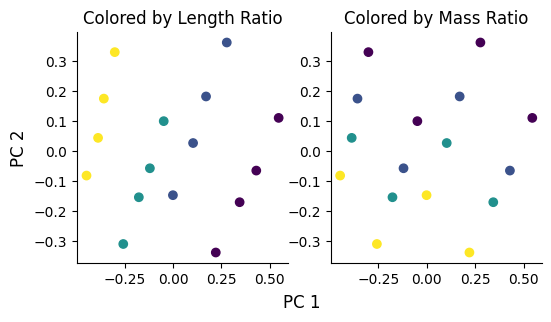

In [17]:
# plot pca subject vectors
colors = [(PENDULUM_PARAMETERS[i]["m1"]/PENDULUM_PARAMETERS[i]["m2"], PENDULUM_PARAMETERS[i]["l1"]/PENDULUM_PARAMETERS[i]["l2"]) for i in range(16)]
pca = PCA(n_components=2)
fig, axs = plt.subplots(1, 2, figsize=(6, 3))
subject_vectors = model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()
subject_vectors_2d = pca.fit_transform(subject_vectors)
axs[0].scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=[colors[i][1] for i in range(16)], cmap="viridis", label="Subject Vectors")
axs[0].set_title("Colored by Length Ratio")
axs[1].scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=[colors[i][0] for i in range(16)], cmap="viridis", label="Subject Vectors")
axs[1].set_title("Colored by Mass Ratio")
axs[0].set_ylabel("PC 2", fontsize=FONT_SIZE)

for ax in axs:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
fig.text(0.5, -0.04, 'PC 1', ha='center', fontsize=FONT_SIZE)
plt.show()
#save_fig(fig, "pendulum_subject_vectors_pca")

## Fine Tuning

In [25]:
RESULTS_PATH = os.path.join(RESULTS_DIR, "pendulum_different_ft")
DEVICE = tc.device("cpu")
RUN = "001"
# load test set
full_ft = tc.as_tensor(np.load(DATA_DIR + "/multi_task_double_pendulum/default/full_ft.npy", allow_pickle=True))

In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:////" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in param_importances.keys():
    print(f"{param} imp: {param_importances[param]:.4f}, best: {best_trial.params.get(param)}")

In [28]:
DATASET_FT = init_dataset(json.load(open(RESULTS_PATH + f"{'/params_dsr_lr=0p00_lr_gamma=1p00_gtf=0p00_gtf_gamma=0p99_aent=56p26_adsr=152p52_ac=0p05_seqlen=44/001'}/config.json")), DEVICE)
MEASUREMENT_INDEX_TO_TS_INDEX_FT = {DATASET_FT.evaluator_test_samples[i].measurement_index: DATASET_FT.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(DATASET_FT.evaluator_test_samples)-1, -1, -1)}
PENDULUM_PARAMETERS_FT = np.load(DATA_DIR + "/multi_task_double_pendulum/default/params_ft.npy", allow_pickle=True)

Sequence length set to 44.


In [30]:
trial = get_trial_by_number(study.trials, 119)
trial_folder_name = "params_" + \
    "_".join([(f"{key}={ValueFormatter._formatted_value(value)}")
             for key, value in trial.params.items()])
print(trial_folder_name)
#trial_folder_name = "params_enc_lr=0p04_dsr_lr=0p00_lr_gamma=1p00_gtf=0p00_gtf_gamma=1p00_aent=4p42_adsr=174p19_ac=2p91"

params_dsr_lr=0p00_lr_gamma=1p00_gtf=0p00_gtf_gamma=0p99_aent=56p26_adsr=152p52_ac=0p05_seqlen=44


In [31]:
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)
parameters_ft = json.load(open(f"{run_path}/config.json"))
model_ft = MTFModel(DATASET_FT, model_path=run_path, device=DEVICE)

Encoder model parameters: 11200
DSR model parameters: 45856
Decoder model parameters: 0


In [32]:
trajectories_train_ft = []
trajectories_val_ft = []
trajectories_test_ft = []

for time_series_index in range(len(DATASET_FT.evaluator_train_samples)):
    observations_train = DATASET_FT.evaluator_train_samples[time_series_index].input
    measurement_index = DATASET_FT.evaluator_train_samples[time_series_index].measurement_index
    cumulative_timeseries_index = DATASET_FT.evaluator_train_samples[time_series_index].cumulative_timeseries_index

    trajectory = model_ft.generate_free_trajectory(
        observations_train,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[2].detach().cpu()
    trajectories_train_ft.append(trajectory)

for time_series_index in range(len(DATASET_FT.evaluator_test_samples)):
    observations_val = DATASET_FT.evaluator_test_samples[time_series_index].input
    measurement_index = DATASET_FT.evaluator_test_samples[time_series_index].measurement_index
    cumulative_timeseries_index = DATASET_FT.evaluator_test_samples[time_series_index].cumulative_timeseries_index

    trajectory = model_ft.generate_free_trajectory(
        observations_val,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[2].detach().cpu()
    trajectories_val_ft.append(trajectory)
    
for i in range(16):
    observations_test = full_ft[i, 1, :600]
    measurement_index = i
    cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX_FT[measurement_index]
    #observations_test[0] =tc.randn(6)
    trajectory = model_ft.generate_free_trajectory(
        observations_test,
        cumulative_timeseries_index,  # One trajectory per subject
        measurement_index,
    )[2].detach().cpu()
    trajectories_test_ft.append(trajectory)

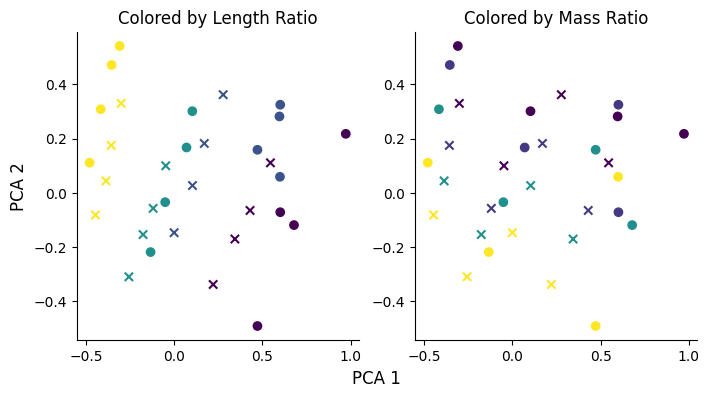

In [34]:
colors = [(PENDULUM_PARAMETERS[i]["m1"]/PENDULUM_PARAMETERS[i]["m2"], PENDULUM_PARAMETERS[i]["l1"]/PENDULUM_PARAMETERS[i]["l2"]) for i in range(16)]
colors_ft = [(PENDULUM_PARAMETERS_FT[i]["m1"]/PENDULUM_PARAMETERS_FT[i]["m2"], PENDULUM_PARAMETERS_FT[i]["l1"]/PENDULUM_PARAMETERS_FT[i]["l2"]) for i in range(16)]# plot pca subject vectors
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
subject_vectors_ft = model_ft.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()
subject_vectors_2d_ft = pca.transform(subject_vectors_ft)
axs[0].scatter(subject_vectors_2d_ft[:, 0], subject_vectors_2d_ft[:, 1], c=[colors[i][1] for i in range(16)], cmap="viridis", label="Subject Vectors")
axs[0].scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=[colors[i][1] for i in range(16)], cmap="viridis", label="Subject Vectors",  marker="x")
axs[0].set_title("Colored by Length Ratio")
axs[1].scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=[colors_ft[i][0] for i in range(16)], cmap="viridis", label="Subject Vectors", marker="x")
axs[1].scatter(subject_vectors_2d_ft[:, 0], subject_vectors_2d_ft[:, 1], c=[colors_ft[i][0] for i in range(16)], cmap="viridis", label="Subject Vectors")
axs[1].set_title("Colored by Mass Ratio")
axs[0].set_ylabel("PCA 2", fontsize=FONT_SIZE)

for ax in axs:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
fig.text(0.5, 0.0, 'PCA 1', ha='center', fontsize=FONT_SIZE)
plt.show()
#save_fig(fig, "pendulum_subject_vectors_pca")